In [ ]:

import multiprocessing
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import scipy
import pytensor.tensor as pt
from scipy.optimize import curve_fit
from scipy.stats import norm
from pytensor.tensor import erf

In [ ]:
plt.rcParams.update({
    "font.family": "serif",
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "legend.fontsize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "figure.figsize": (5.8, 3.6),  # tipico per colonna singola
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
})

In [ ]:

def add_peak(ax, x, text, y_text, y_line_top=200):
    """
    ax       : axis
    x        : posizione del picco (keV)
    text     : label da scrivere
    y_text   : posizione testo
    y_line_top : altezza linea verticale
    """

    # linea verticale tratteggiata
    ax.vlines(
        x,
        0,
        y_line_top,
        ls='--',
        color='black',
        alpha=0.75
    )

    # annotazione (ruotata come nel tuo esempio)
    ax.annotate(
        text,
        xy=(x - 3, y_text),
        rotation=90,
        fontsize=11
    )

In [ ]:
# ============================================================
# ENERGY RESOLUTION
# ============================================================
def sigma_fun(E):

    A = 3.68436e1
    B = 1.72714e4

    return (
        E * pt.sqrt(A/E + B/E**2)
        / 2.355
        / 100
    )

In [ ]:

# ============================================================
# DATA LOADING
# ============================================================
def load_spectrum(file_path, calibration, energy_range=(0, 3000)):
    """
    Load raw spectrum and convert channels to energy.
    """

    data = pd.read_csv(file_path, header=None)
    spectrum = data[0].to_numpy(dtype=np.float64)

    channels = np.arange(len(spectrum))

    E = (
        channels * calibration["a"]
        + calibration["b"]
        + calibration["c"] * channels**2
    )

    mask = (E >= energy_range[0]) & (E <= energy_range[1])

    return E[mask], spectrum[mask]

In [ ]:
# ============================================================
# HISTOGRAMMING
# ============================================================
def make_histogram(E, spectrum, bins):
    counts, edges = np.histogram(E, bins=bins, weights=spectrum)
    centers = 0.5 * (edges[1:] + edges[:-1])

    return centers, edges, counts



In [ ]:

# ============================================================
# GAUSSIAN MODEL
# ============================================================
def gaussian_plus_bg(E, mu, sigma, area, background):
    """
    Gaussian normalized to total area + flat background.
    """

    gaussian = (
        area
        / (sigma * np.sqrt(2 * np.pi))
        * np.exp(-0.5 * ((E - mu) / sigma) ** 2)
    )

    return gaussian + background


In [ ]:

# ============================================================
# BUILD TOTAL DATASET
# ============================================================
def build_total_spectrum(files_config, bins):
    all_histograms = []
    total_time = 0

    for key, cfg in files_config.items():
        E, spectrum = load_spectrum(
            cfg["path"],
            cfg["calibration"],
            ENERGY_RANGE,
        )

        E_centers, E_edge,  counts = make_histogram(E, spectrum, bins)

        all_histograms.append(counts)
        total_time += cfg["time"]

    total_counts = np.sum(all_histograms, axis=0)

    return E_centers, E_edge,  total_counts, total_time

# inizio

In [38]:
FILES = {
    "50d": {
        "path": "csv-files/zro2_white&green_ 50_days.csv",
        "time": 4279386,
        "calibration": {
            "a": 0.357304,
            "b": -0.295444,
            "c": 1.352297e-9,
        },
    },
    "90d": {
        "path": "csv-files/90_days.csv",
        "time": 7550023,
        "calibration": {
            "a": 4.179423e-01,
            "b": 1.2696e-01,
            "c": 1.514025e-08,
        },
    },
}

In [39]:
ENERGY_RANGE = (0, 3000)
BIN_WIDTH = 0.42

BINS = np.arange(ENERGY_RANGE[0], ENERGY_RANGE[1], BIN_WIDTH)

BACKGROUND_PEAKS = {

   "???" : {"E":860.45, "N":0},
   "84Rb":  {"E":881.6, "N":0},
    "88Y":  {"E":898, "N":0},
    "228Ac":  {"E":911.204, "N":0}
}

BACKGROUND_PEAKS = {

   "208Tl" : {"E":860.45, "N":0},
   "84Rb":  {"E":881.6, "N":0},
    "88Y":  {"E":898, "N":0},
    "228Ac":  {"E":911.204, "N":0}
}

BACKGROUND_PEAKS = {

    "²⁰⁸Tl": {"E": 860.45, "N": 0},
    "⁸⁴Rb":  {"E": 881.6,  "N": 0},
    "⁸⁸Y":   {"E": 898,    "N": 0},
    "²²⁸Ac": {"E": 911.204, "N": 0}
}



SIGNAL = {
    "mu": 871,
    "roi": (840, 920),
}

SAMPLING_CONFIG = {
    "draws": 2000,
    "tune": 2000,
    "chains": 4,
    "target_accept": 0.95,
}


In [40]:
E_tot, E_edge, Ntot, t_tot = build_total_spectrum(FILES, BINS)


print(
    f"Total counts = {np.sum(Ntot):.0f} "
    f"in {t_tot / (60 * 60 * 24):.1f} days"
)

Total counts = 42047 in 136.9 days


(35.0, 500.0)

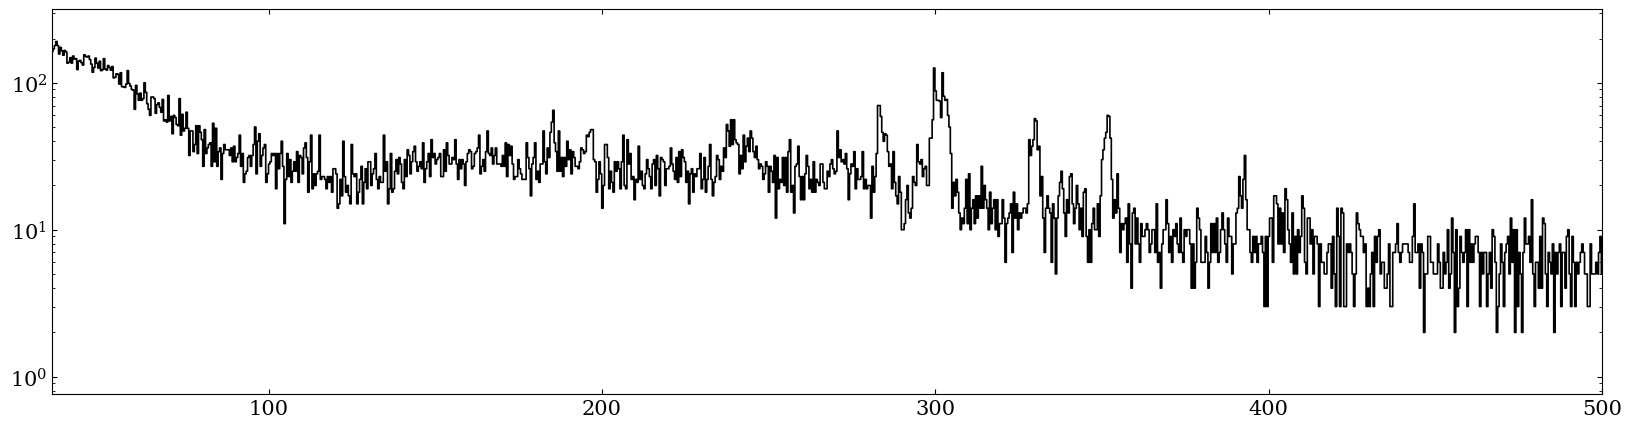

In [41]:
plt.figure(figsize=(20,5))
plt.step(E_tot, Ntot, where="mid", color="black")
plt.yscale('log')
plt.vlines(1460, 1, 100, color='red', linestyle='dashed')
plt.xlim(35,500)

In [42]:
roi_mask = (
    (E_tot > SIGNAL["roi"][0]) &
    (E_tot < SIGNAL["roi"][1])
)

E_roi = E_tot[roi_mask]
counts_roi = Ntot[roi_mask]

In [43]:
bin_edges = BINS
bin_centers = 0.5 * (bin_edges[:-1] + bin_edges[1:])

# ============================================================
# ROI
# ============================================================
roi_mask = (
    (bin_centers >= SIGNAL["roi"][0]) &
    (bin_centers <= SIGNAL["roi"][1])
)

# Conteggi nella ROI
counts_roi = Ntot[roi_mask]

# Centri dei bin nella ROI
E_roi = bin_centers[roi_mask]

# Edge dei bin nella ROI
idx = np.where(roi_mask)[0]
bin_edges_roi = bin_edges[idx[0]:idx[-1] + 2]

# Larghezza dei bin (costante)
bin_width = bin_edges_roi[1] - bin_edges_roi[0]


In [48]:


edges_low = bin_edges_roi[:-1]
edges_high = bin_edges_roi[1:]

# ============================================================
# CDF GAUSSIAN (PyTensor safe)
# ============================================================
def gaussian_cdf(x, mu, sigma):
    return 0.5 * (1.0 + pt.erf((x - mu) / (sigma * pt.sqrt(2.0))))

def bin_integral(mu, sigma, low, high):
    return gaussian_cdf(high, mu, sigma) - gaussian_cdf(low, mu, sigma)

# ============================================================
# MODEL
# ============================================================
with pm.Model() as model:
    # ========================================================
    # BACKGROUND PEAKS
    # ========================================================
    A_bg = []
    mu_bg = []

    for name in BACKGROUND_PEAKS:

        fit = BACKGROUND_PEAKS[name]

        #A = pm.HalfNormal(f"A_{name}", sigma=np.max(counts_roi)/2)
        A = pm.HalfFlat(f"A_{name}")
        mu = pm.Normal(f"mu_{name}", mu=fit["E"], sigma=0.5)

        A_bg.append(A)
        mu_bg.append(mu)

    A_bg = pt.stack(A_bg)
    mu_bg = pt.stack(mu_bg)

    # ========================================================
    # SIGNAL
    # ========================================================
    #A_signal = pm.HalfNormal("A_signal", sigma=np.max(counts_roi))
    A_signal = pm.HalfFlat("A_signal")
    mu_signal = pm.Normal("mu_signal", mu=SIGNAL["mu"], sigma=0.25)

    sigma = sigma_fun(mu_signal)  # must be PyTensor-compatible

    # ========================================================
    # FLAT BACKGROUND
    # ========================================================
    bin_width = edges_high - edges_low



    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi)
    )



    Q_bins = Q * bin_width
    '''
    Q = pm.HalfNormal(
        "Q",
        sigma=np.mean(counts_roi)
    )

    Q_bins = Q * np.ones_like(edges_low) '''   
    
    
    # ========================================================
    # EXACT BIN INTEGRALS
    # ========================================================
    sig = bin_integral(mu_signal, sigma, edges_low, edges_high)

    bg = pt.stack([
        bin_integral(mu_bg[i], sigma, edges_low, edges_high)
        for i in range(len(BACKGROUND_PEAKS))
    ])

    # ========================================================
    # EXPECTATION PER BIN
    # ========================================================
    lambda_E = (
        Q_bins
        + A_signal * sig
        + pt.sum(A_bg[:, None] * bg, axis=0)
    )

    lambda_E = pt.clip(lambda_E, 1e-9, np.inf)

    # ========================================================
    # LIKELIHOOD
    # ========================================================
    pm.Poisson(
        "obs",
        mu=lambda_E,
        observed=counts_roi
    )

   

    # ========================================================
    # SAMPLING
    # ========================================================
    trace = pm.sample(
        draws=2000,
        tune=4000,
        chains=4,
        cores=min(4, multiprocessing.cpu_count()),
        target_accept=0.95,
        init="jitter+adapt_diag",
        return_inferencedata=True,
        progressbar=False,
    )




Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [A_²⁰⁸Tl, mu_²⁰⁸Tl, A_⁸⁴Rb, mu_⁸⁴Rb, A_⁸⁸Y, mu_⁸⁸Y, A_²²⁸Ac, mu_²²⁸Ac, A_signal, mu_signal, Q]
Sampling 4 chains for 4_000 tune and 2_000 draw iterations (16_000 + 8_000 draws total) took 12 seconds.


In [49]:
summary = az.summary(trace, round_to=4)
summary

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
mu_²⁰⁸Tl,860.7833,0.2851,860.2605,861.3359,0.0032,0.0039,8257.5687,4677.4907,1.0000
mu_⁸⁴Rb,881.4863,0.3818,880.8171,882.2610,0.0041,0.0048,8707.2877,5582.7778,1.0003
mu_⁸⁸Y,898.1214,0.1001,897.9448,898.3134,0.0011,0.0012,8954.7022,4950.3122,1.0007
mu_²²⁸Ac,911.1296,0.1289,910.8895,911.3758,0.0014,0.0015,8605.1981,5764.4838,1.0002
mu_signal,871.0401,0.2524,870.5746,871.5247,0.0026,0.0031,9661.3057,6282.4806,1.0003
A_²⁰⁸Tl,22.4635,6.7116,9.5391,34.7128,0.0764,0.0822,7122.6174,4048.0565,1.0001
A_⁸⁴Rb,8.2672,4.8356,0.0209,16.4255,0.0572,0.0569,5454.2999,3326.5814,1.0000
A_⁸⁸Y,146.5247,13.6728,120.4431,171.9400,0.1441,0.1625,8827.7486,5799.7946,1.0005
A_²²⁸Ac,91.9502,10.8941,71.8315,112.2644,0.1131,0.1300,9167.8211,5760.0332,1.0000
A_signal,4.4691,3.4417,0.0000,10.6812,0.0358,0.0426,5895.4835,3354.8261,1.0004


In [50]:
counts_isotopes = [v for v in trace.posterior.data_vars if v.startswith("A_")]

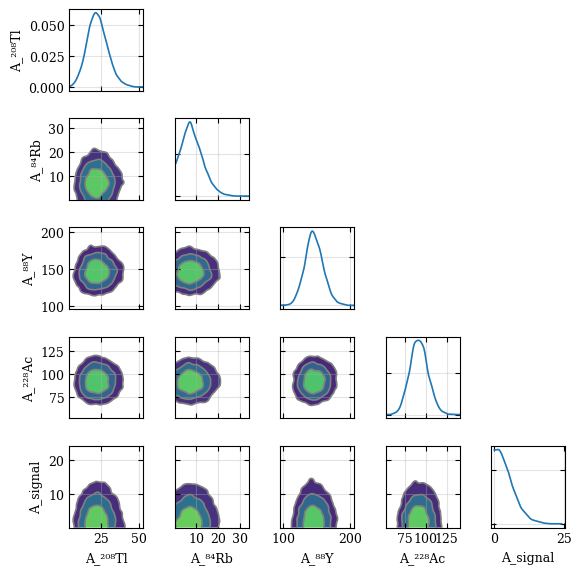

In [51]:
A_vars = [v for v in trace.posterior.data_vars if v.startswith("A_")]

axes = az.plot_pair(
    trace,
    var_names=A_vars,
    kind="kde",
    marginals=True,
    figsize=(6, 6),
    textsize=9
)

for ax in axes.flatten():
    ax.grid(alpha=0.35)

plt.tight_layout()
plt.savefig("plots/trace_pair_plot.png", dpi=300)
plt.show()

In [52]:


# ============================================================
# POSTERIOR OF SIGNAL
# ============================================================
signal_samples = trace.posterior["A_signal"].values.flatten()

N_signal_90 = np.percentile(signal_samples, 90)
N_signal_95 = np.percentile(signal_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on signal counts : {N_signal_90:.3f}")
print(f"95% upper limit on signal counts : {N_signal_95:.3f}")
print("=" * 60)


90% upper limit on signal counts : 9.202
95% upper limit on signal counts : 11.178


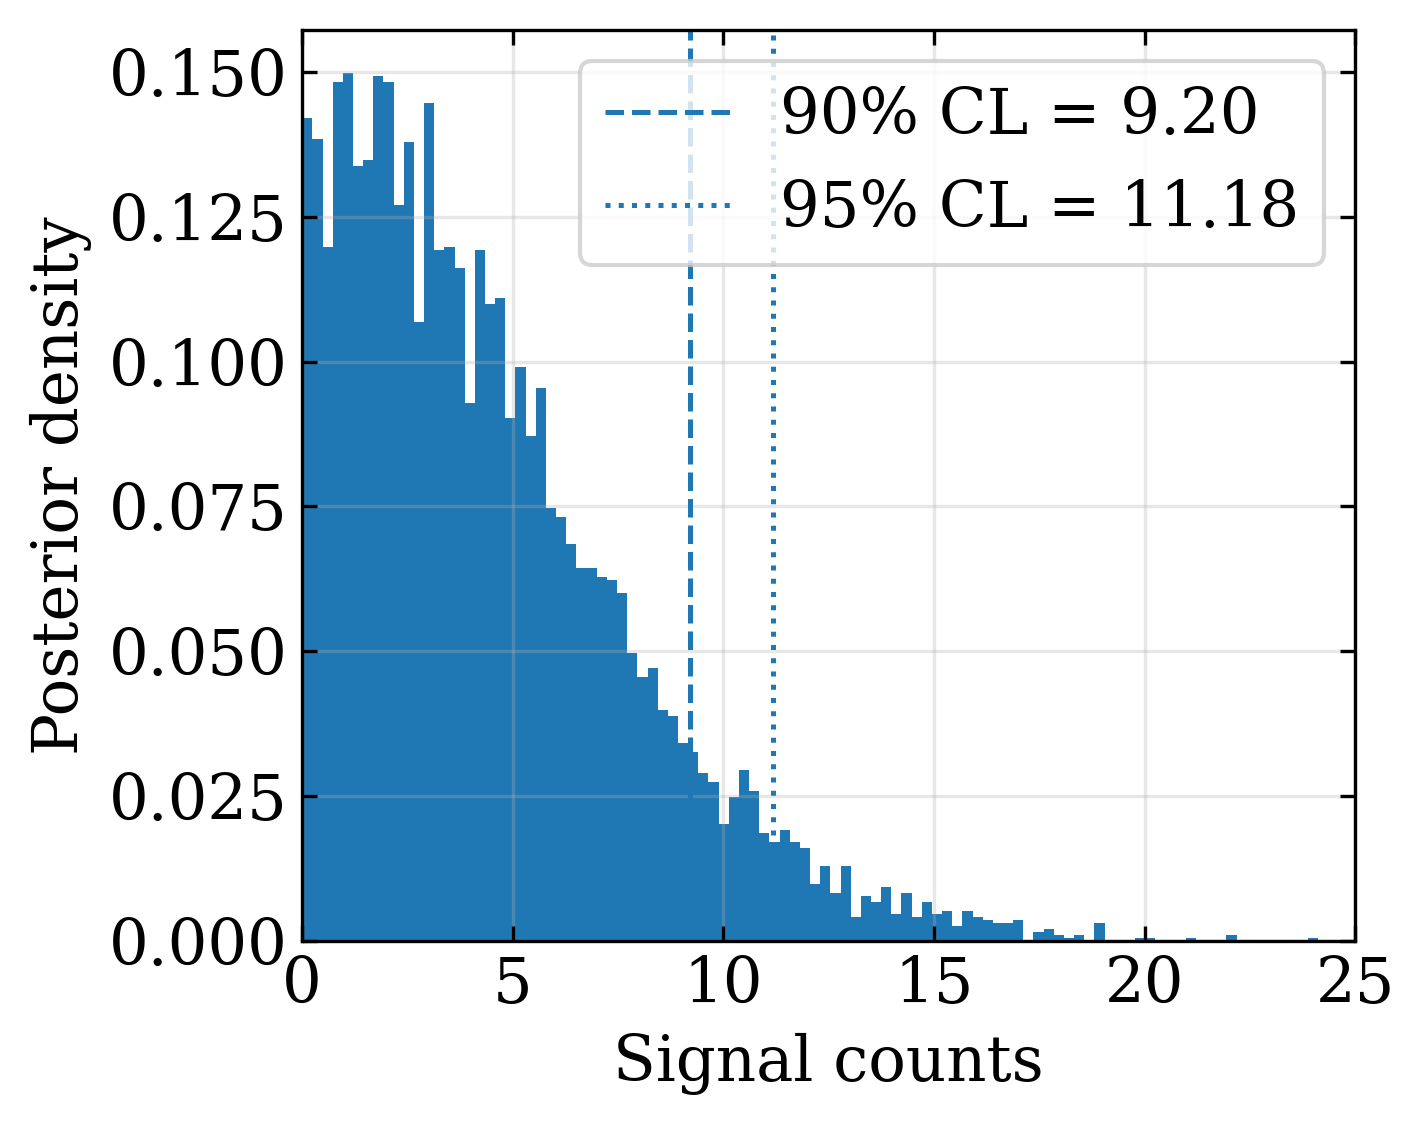

In [53]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(5,4), dpi=300)

plt.hist(signal_samples, bins=100, density=True)

plt.axvline(
    N_signal_90,
    linestyle="--",
    label=f"90% CL = {N_signal_90:.2f}",
)

plt.axvline(
    N_signal_95,
    linestyle=":",
    label=f"95% CL = {N_signal_95:.2f}",
)

plt.xlabel("Signal counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.xlim(0,25)
plt.legend()

plt.tight_layout()
plt.show()



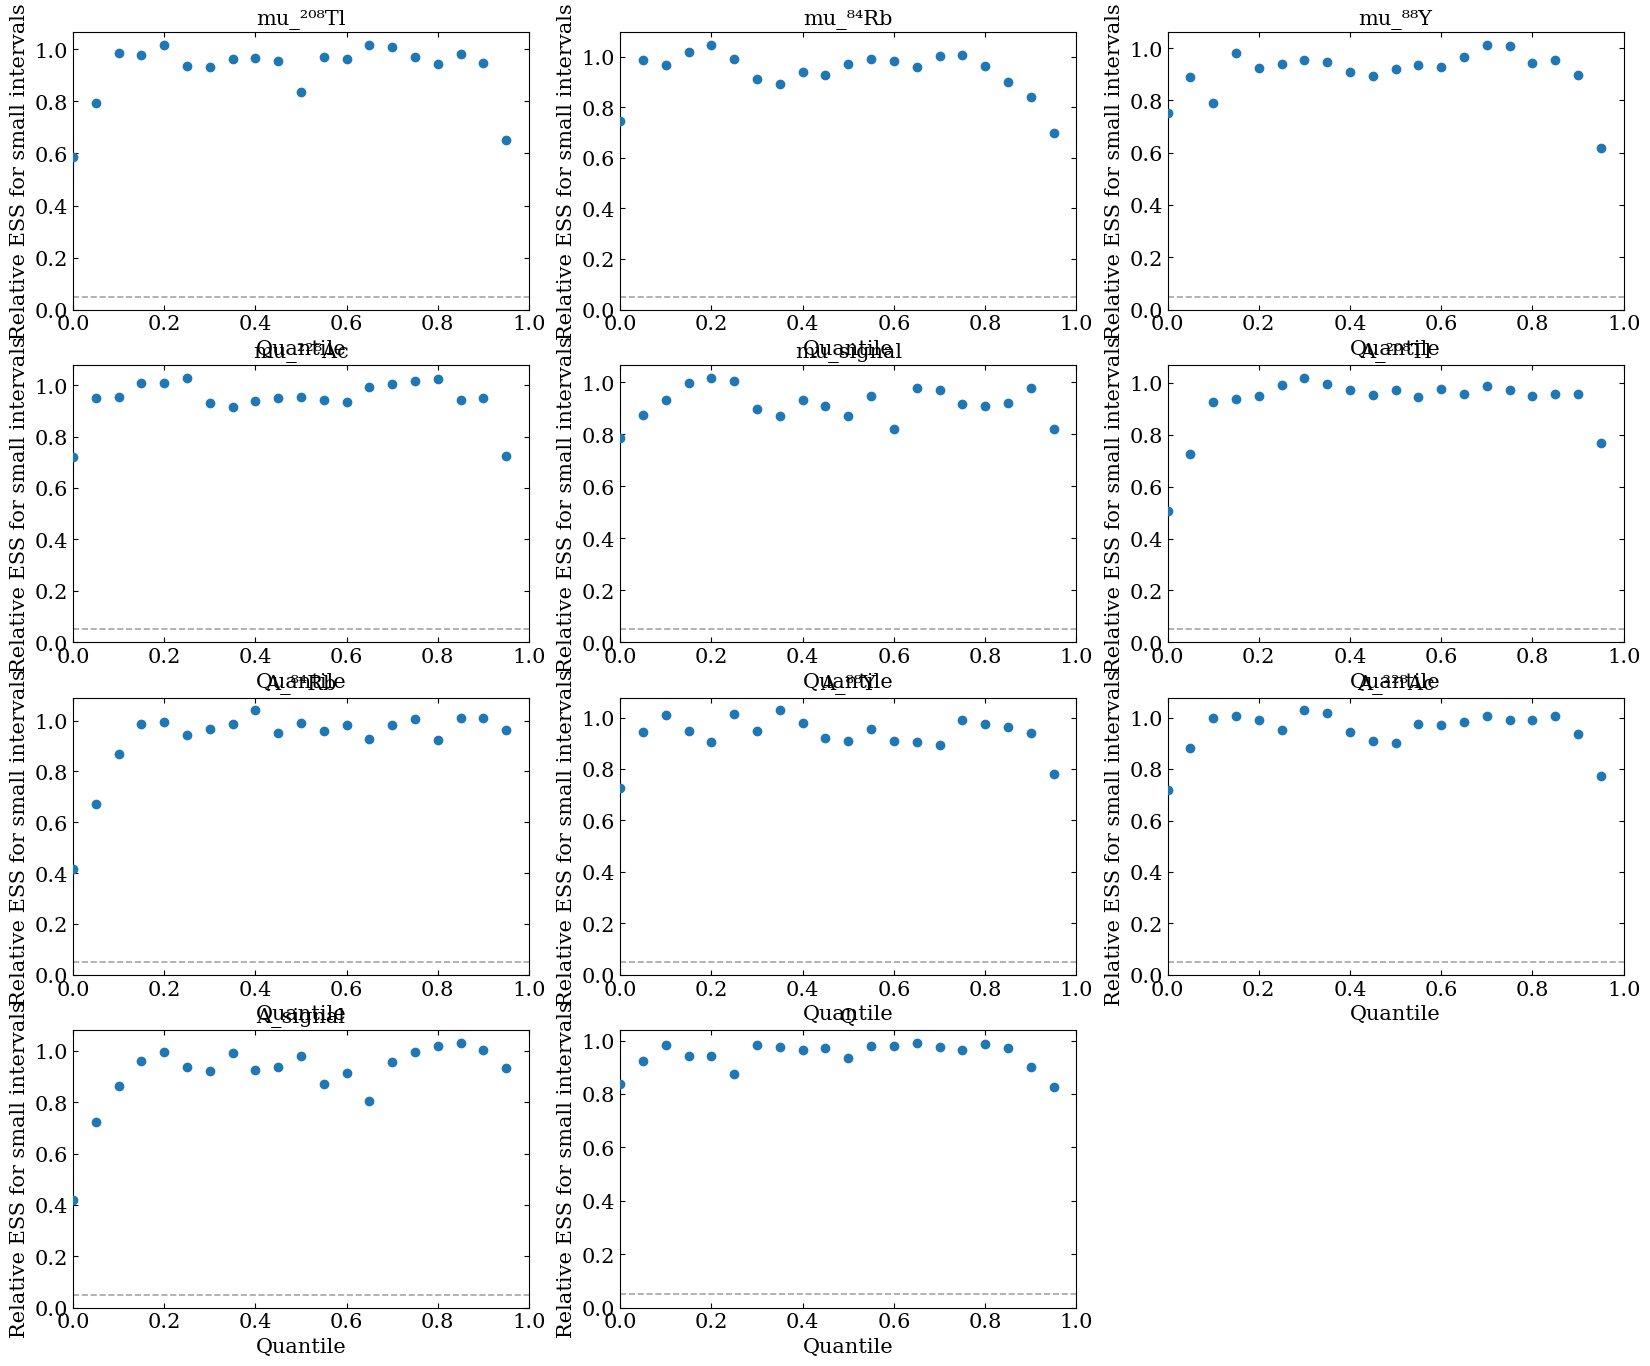

In [54]:
#az.plot_trace(trace, compact=True, legend=True)
az.plot_ess(trace, kind="local", relative=True);
#Higher local ESS the better, indicating more efficient Markov Chains

#Efficient Markov Chains should demonstrate Relative ESS values that

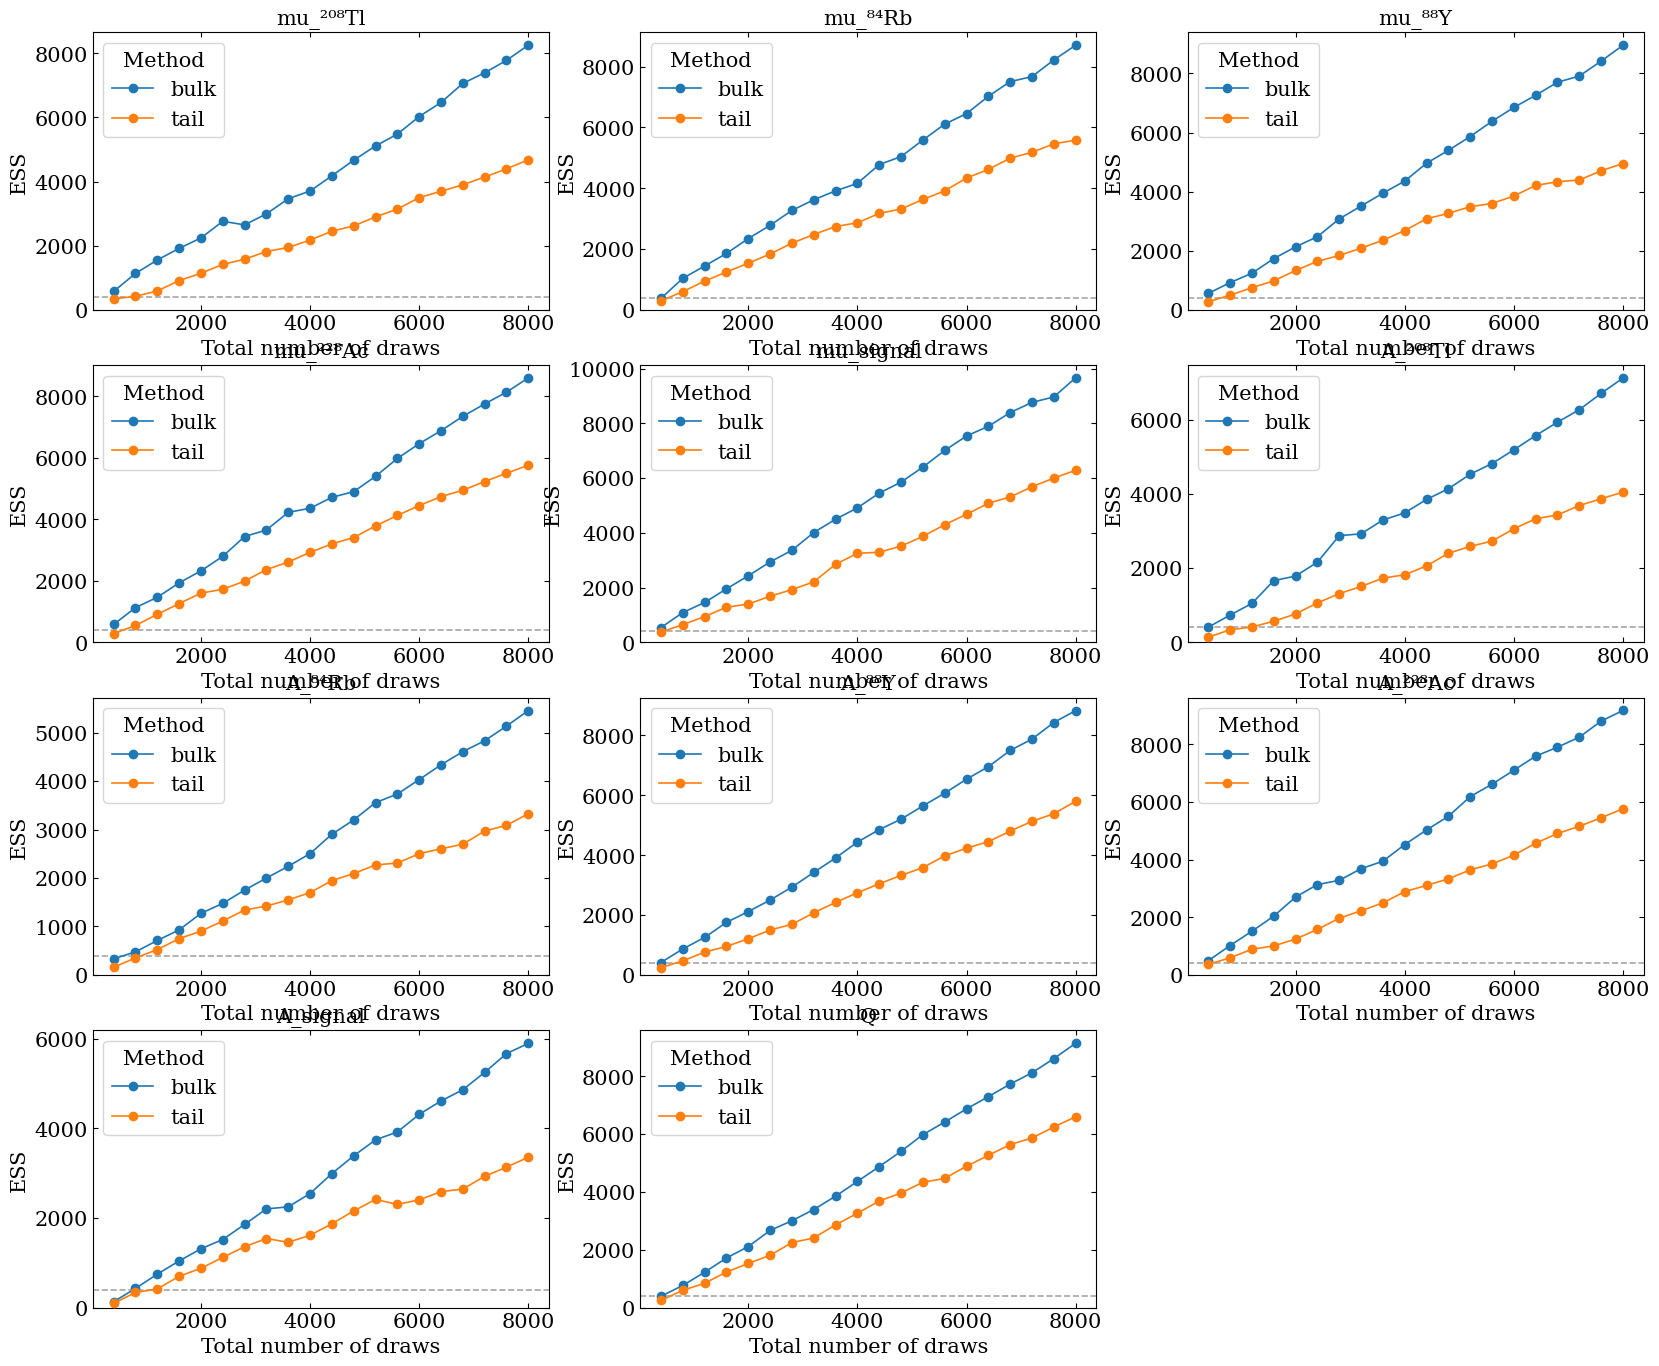

In [55]:
az.plot_ess(trace, kind="evolution");
#For Markov Chains that are converging, ESS should increase consistently with the number of draws from the chain

#ESS vs draws should be roughly linear for both bulk and tail

In [56]:
# posterior extraction
# ============================================================
# POSTERIOR EXTRACTION
# ============================================================

background_names = list(BACKGROUND_PEAKS.keys())

idata = trace
posterior = idata.posterior

Q_s = posterior["Q"].values.reshape(-1)

A_signal_s = posterior["A_signal"].values.reshape(-1)
mu_signal_s = posterior["mu_signal"].values.reshape(-1)

A_bg_s = {
    name: posterior[f"A_{name}"].values.reshape(-1)
    for name in background_names
}

mu_bg_s = {
    name: posterior[f"mu_{name}"].values.reshape(-1)
    for name in background_names
}

In [58]:
import numpy as np
import scipy.special


# ============================================================
# ESTRAZIONE POSTERIOR DEI PARAMETRI
# ============================================================

posterior = trace.posterior

n_samples = (
    posterior.sizes["chain"]
    *
    posterior.sizes["draw"]
)

print(f"Number of posterior samples: {n_samples}")


# ============================================================
# SIGNAL PARAMETERS
# ============================================================

A_signal_s = (
    posterior["A_signal"]
    .values
    .flatten()
)

mu_signal_s = (
    posterior["mu_signal"]
    .values
    .flatten()
)


# ============================================================
# FLAT BACKGROUND
# ============================================================

Q_s = (
    posterior["Q"]
    .values
    .flatten()
)



# ============================================================
# BACKGROUND PEAK PARAMETERS
# ============================================================

A_bg_s = []
mu_bg_s = []


for name in BACKGROUND_PEAKS:

    A_bg_s.append(
        posterior[f"A_{name}"]
        .values
        .flatten()
    )

    mu_bg_s.append(
        posterior[f"mu_{name}"]
        .values
        .flatten()
    )


# trasformo in numpy array

A_bg_s = np.array(A_bg_s)

mu_bg_s = np.array(mu_bg_s)



print("A_bg shape:", A_bg_s.shape)
print("mu_bg shape:", mu_bg_s.shape)



# ============================================================
# STORAGE DELLE CURVE POSTERIOR
# ============================================================

lambda_total_samples = []

lambda_bkg_samples = []

n_samples = 2000

# ============================================================
# LOOP SUI CAMPIONI POSTERIOR
# ============================================================

for i in range(n_samples):


    # --------------------------------------------------------
    # ENERGY DEPENDENT RESOLUTION
    # --------------------------------------------------------

    mu_sig = mu_signal_s[i]

    sigma_i = sigma_fun(mu_sig).eval()



    # --------------------------------------------------------
    # SIGNAL CONTRIBUTION
    # --------------------------------------------------------

    sig_integral = (
        0.5 *
        (
            1
            +
            scipy.special.erf(
                (edges_high - mu_sig)
                /
                (sigma_i*np.sqrt(2))
            )
        )
        -
        0.5 *
        (
            1
            +
            scipy.special.erf(
                (edges_low - mu_sig)
                /
                (sigma_i*np.sqrt(2))
            )
        )
    )


    signal_i = (
        A_signal_s[i]
        *
        sig_integral
    )



    # --------------------------------------------------------
    # BACKGROUND PEAKS
    # --------------------------------------------------------

    bg_i = np.zeros_like(edges_low)



    for j in range(len(BACKGROUND_PEAKS)):


        mu_bg_i = mu_bg_s[j,i]


        bg_integral = (
            0.5 *
            (
                1
                +
                scipy.special.erf(
                    (edges_high - mu_bg_i)
                    /
                    (sigma_i*np.sqrt(2))
                )
            )
            -
            0.5 *
            (
                1
                +
                scipy.special.erf(
                    (edges_low - mu_bg_i)
                    /
                    (sigma_i*np.sqrt(2))
                )
            )
        )


        bg_i += (
            A_bg_s[j,i]
            *
            bg_integral
        )



    # --------------------------------------------------------
    # FLAT BACKGROUND
    # --------------------------------------------------------
    
    flat_i = (
        Q_s[i]
        *
        bin_width
    )
    #flat_i = Q_s[i] * np.ones_like(edges_low)



    # --------------------------------------------------------
    # ONLY BACKGROUND
    # --------------------------------------------------------

    bkg_model_i = (
        flat_i
        +
        bg_i
    )



    # --------------------------------------------------------
    # TOTAL MODEL
    # --------------------------------------------------------

    total_model_i = (
        bkg_model_i
        +
        signal_i
    )



    lambda_bkg_samples.append(
        bkg_model_i
    )


    lambda_total_samples.append(
        total_model_i
    )



# ============================================================
# ARRAY FINALI
# ============================================================

lambda_bkg_samples = np.array(
    lambda_bkg_samples
)


lambda_total_samples = np.array(
    lambda_total_samples
)



print(
    "Total posterior curves:",
    lambda_total_samples.shape
)

print(
    "Background posterior curves:",
    lambda_bkg_samples.shape
)



# ============================================================
# STATISTICHE POSTERIOR
# ============================================================


# ---- TOTAL MODEL ----

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)


lambda_total_low = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)


lambda_total_high = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)



# ---- BACKGROUND ONLY ----

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)


lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)


lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)



print("Done.")

Number of posterior samples: 8000
A_bg shape: (4, 8000)
mu_bg shape: (4, 8000)


AssertionError: 
Apply node that caused the error: DeepCopyOp(0.9433330485885939)
Toposort index: 0
Inputs types: [TensorType(float64, shape=())]

HINT: Use a linker other than the C linker to print the inputs' shapes and strides.
HINT: Re-running with most PyTensor optimizations disabled could provide a back-trace showing when this node was created. This can be done by setting the PyTensor flag 'optimizer=fast_compile'. If that does not work, PyTensor optimizations can be disabled with 'optimizer=None'.
HINT: Use the PyTensor flag `exception_verbosity=high` for a debug print-out and storage map footprint of this Apply node.

In [ ]:
# ============================================================
# POSTERIOR SUMMARY
# ============================================================

# totale
fit_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

fit_total_low_68 = np.percentile(
    lambda_total_samples,
    16,
    axis=0
)

fit_total_high_68 = np.percentile(
    lambda_total_samples,
    84,
    axis=0
)


fit_total_low_95 = np.percentile(
    lambda_total_samples,
    2.5,
    axis=0
)

fit_total_high_95 = np.percentile(
    lambda_total_samples,
    97.5,
    axis=0
)



# background
fit_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

fit_bkg_low_68 = np.percentile(
    lambda_bkg_samples,
    16,
    axis=0
)

fit_bkg_high_68 = np.percentile(
    lambda_bkg_samples,
    84,
    axis=0
)


fit_bkg_low_95 = np.percentile(
    lambda_bkg_samples,
    2.5,
    axis=0
)

fit_bkg_high_95 = np.percentile(
    lambda_bkg_samples,
    97.5,
    axis=0
)

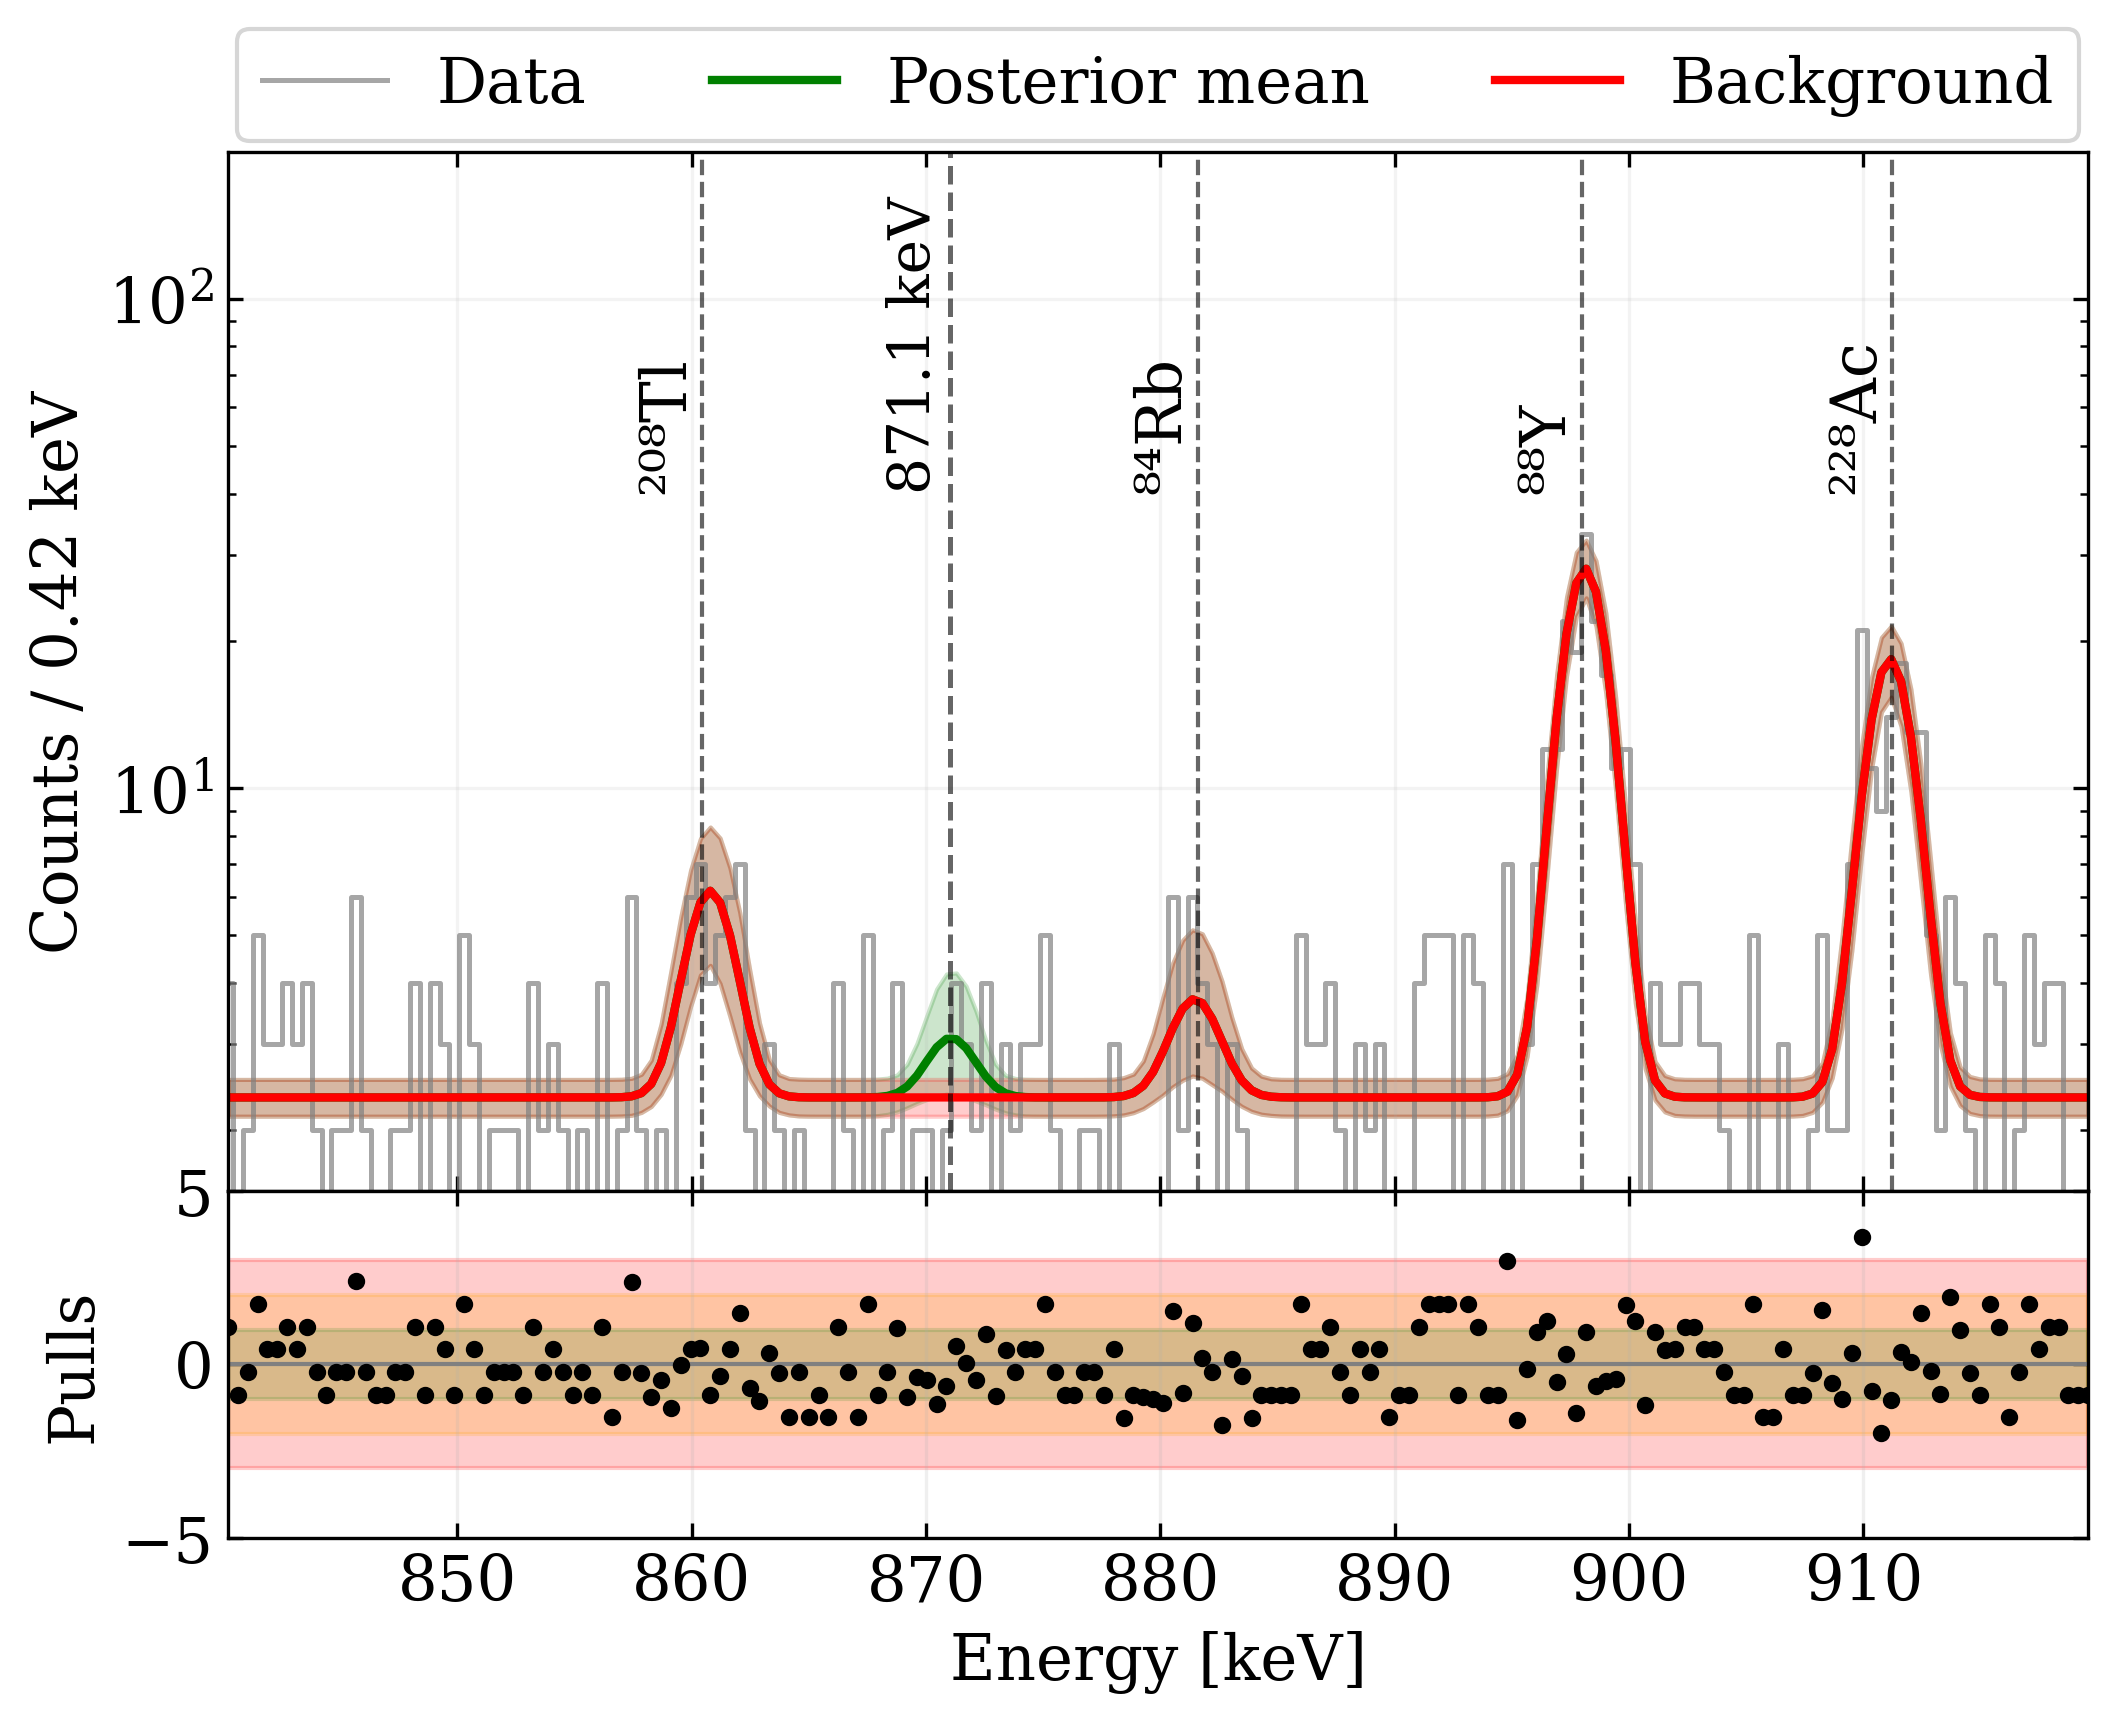

In [ ]:
# ============================================================
# BAYESIAN FIT BAND
# ============================================================

# lambda_total_samples:
# (N_posterior_samples, N_bins)

lambda_total_mean = np.mean(
    lambda_total_samples,
    axis=0
)

lambda_total_low = np.percentile(
    lambda_total_samples,
    5,
    axis=0
)

lambda_total_high = np.percentile(
    lambda_total_samples,
    95,
    axis=0
)


# background only

lambda_bkg_mean = np.mean(
    lambda_bkg_samples,
    axis=0
)

lambda_bkg_low = np.percentile(
    lambda_bkg_samples,
    5,
    axis=0
)

lambda_bkg_high = np.percentile(
    lambda_bkg_samples,
    95,
    axis=0
)



# ============================================================
# RESIDUALS
# ============================================================

residuals = (
    counts_roi - lambda_total_mean
) / np.sqrt(lambda_total_mean + 1e-9)



# ============================================================
# BIN CENTERS
# ============================================================

E_roi = 0.5*(edges_low + edges_high)



# ============================================================
# FIGURE
# ============================================================

fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    sharex=True,
    gridspec_kw={"height_ratios": [3,1]},
    figsize=(8,6),
    dpi = 300
)



# ============================================================
# DATA
# ============================================================

ax1.step(
    E_roi,
    counts_roi,
    where="mid",
    color="grey",
    alpha=0.7,
    label="Data"
)



# ============================================================
# TOTAL BAYESIAN MODEL
# ============================================================

ax1.plot(
    E_roi,
    lambda_total_mean,
    #where="mid",
    color="green",
    lw=2,
    label="Posterior mean"
)


ax1.fill_between(
    E_roi,
    lambda_total_low,
    lambda_total_high,
    #step="mid",
    color="green",
    alpha=0.2,
    #label="68% credible interval"
)



# ============================================================
# BACKGROUND ONLY
# ============================================================

ax1.plot(
    E_roi,
    lambda_bkg_mean,
    #where="mid",
    color="red",
    lw=2,
    label="Background"
)


ax1.fill_between(
    E_roi,
    lambda_bkg_low,
    lambda_bkg_high,
    #step="mid",
    color="red",
    alpha=0.2
)



# ============================================================
# BACKGROUND PEAK LINES
# ============================================================

for name, peak in BACKGROUND_PEAKS.items():

    ax1.axvline(
        peak["E"] ,
        color="black",
        linestyle="--",
        alpha=0.6,
        lw=1
    )

    ax1.text(
        peak["E"] - 1.5,
        40,
        name,
        rotation=90,
        verticalalignment="bottom",
        horizontalalignment="center",
        fontsize=15
    )



# ============================================================
# SIGNAL LINE
# ============================================================

ax1.axvline(
    SIGNAL["mu"],
    color="black",
    linestyle="--",
    alpha=0.6
)


ax1.text(
    SIGNAL["mu"]-1.5,
    40,
    "871.1 keV",
    rotation=90,
    verticalalignment="bottom",
    horizontalalignment="center",
    fontsize=14
)



# ============================================================
# AXES
# ============================================================

ax1.set_yscale("log")

ax1.set_xlim(
    E_roi.min(),
    E_roi.max()
)


ax1.set_ylim(
    1.5,
    200
    
)


ax1.set_ylabel(
    f"Counts / {edges_high[0]-edges_low[0]:.2f} keV"
)


ax1.grid(alpha=0.15)


ax1.legend(
    loc="lower center",
    bbox_to_anchor=(0.5,0.98),
    ncol=3
)



# ============================================================
# RESIDUALS
# ============================================================

ax2.scatter(
    E_roi,
    residuals,
    s=10,
    color="black",
    zorder = 5
)


ax2.axhspan(
    -3,
    3,
    color="red",
    alpha=0.2
)


ax2.axhspan(
    -2,
    2,
    color="orange",
    alpha=0.2
)


ax2.axhspan(
    -1,
    1,
    color="green",
    alpha=0.15
)


ax2.axhline(
    0,
    color="gray",
    lw=1,
    zorder=2
)



ax2.set_xlabel(
    "Energy [keV]"
)


ax2.set_ylabel(
    "Pulls"
)


ax2.set_ylim(
    -5,
    5
)


ax2.grid(alpha=0.2)



plt.subplots_adjust(hspace=0)
plt.savefig("plots/94Zr_fit.pdf", dpi=300, bbox_inches="tight"
)

In [ ]:
import arviz as az

az.summary(
    trace,
    var_names=["Q","A_signal"]
)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
Q,5.544,0.293,4.988,6.084,0.003,0.003,8869.0,5215.0,1.0
A_signal,4.413,3.435,0.002,10.555,0.037,0.040,5247.0,2776.0,1.0


# half life

In [ ]:

# Dati campione
m_sample = 551.3        # mass ZrO2 in grams
Mr_sample = 123.22      # ZrO2 [g/mol]
N_A = 6.022e23          
eff_94Zr = 0.022935  # eff
i_a_94Zr = 0.1738       # isotopic abundance
t_live =    t_tot/(60*60*24*365)             # years

N_nuclei = (m_sample * i_a_94Zr / Mr_sample) * N_A


In [ ]:
N_signal_90 

np.float64(9.258489611690703)

In [ ]:
N_signal_90= 9.3


In [ ]:
# Numero di nuclei 96Zr nel campione
N_nuclei = (m_sample * i_a_94Zr / Mr_sample) * N_A

percentile = 90
T_half_limit = (np.log(2) * N_nuclei * eff_94Zr * t_live) /N_signal_90
print(f"T1/2 > {T_half_limit:.2e} yrs at {percentile}%")

T1/2 > 3.00e+20 yrs at 90%


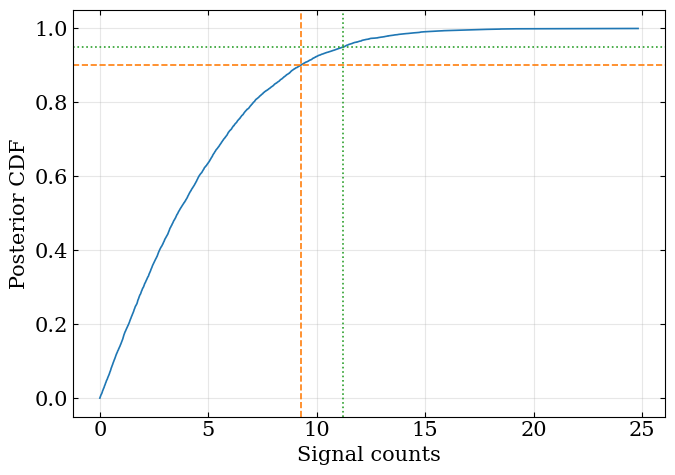

In [ ]:
x = np.sort(signal_samples)
cdf = np.arange(1, len(x)+1)/len(x)

plt.figure(figsize=(7,5))

plt.plot(x, cdf)

plt.axhline(0.90, ls="--", color="C1")
plt.axhline(0.95, ls=":", color="C2")

plt.axvline(N_signal_90, ls="--", color="C1")
plt.axvline(N_signal_95, ls=":", color="C2")

plt.xlabel("Signal counts")
plt.ylabel("Posterior CDF")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

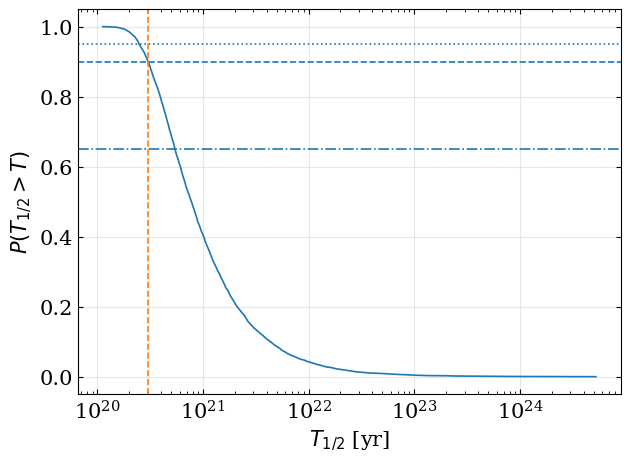

In [ ]:
K = np.log(2) * N_nuclei * eff_94Zr * t_live

T_samples = K / signal_samples
T_samples = T_samples[np.isfinite(T_samples)]

T = np.sort(T_samples)

survival = 1 - np.arange(1, len(T)+1)/len(T)

plt.figure(figsize=(7,5))

plt.plot(T, survival)

plt.xscale("log")

plt.axhline(0.90, ls='--')
plt.axhline(0.95, ls=':')
plt.axhline(0.65, ls='-.')
plt.axvline(T_half_limit, ls='--', color="C1", label=f"90% CL = {T_half_limit:.2e} yrs")


plt.xlabel(r"$T_{1/2}$ [yr]")
plt.ylabel(r"$P(T_{1/2}>T)$")

plt.grid(alpha=0.3)

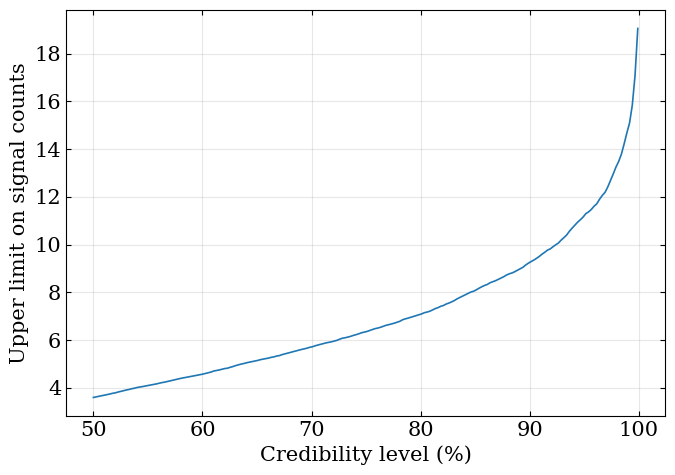

In [ ]:
cls = np.linspace(50, 99.9, 200)
limits = np.percentile(signal_samples, cls)

plt.figure(figsize=(7,5))

plt.plot(cls, limits)

plt.xlabel("Credibility level (%)")
plt.ylabel("Upper limit on signal counts")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

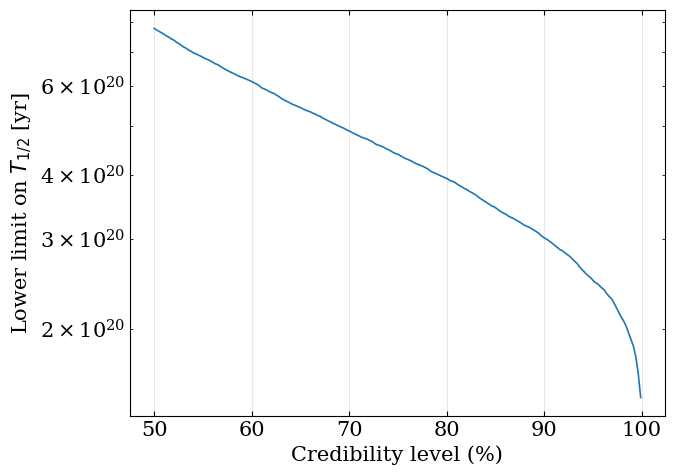

In [ ]:
K = np.log(2) * N_nuclei * eff_94Zr * t_live

T_limits = K / limits

plt.figure(figsize=(7,5))

plt.plot(cls, T_limits)

plt.yscale("log")

plt.xlabel("Credibility level (%)")
plt.ylabel(r"Lower limit on $T_{1/2}$ [yr]")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

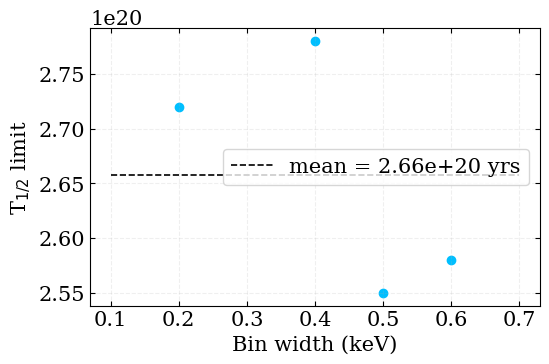

In [ ]:
limit = [2.72e+20, 2.78e+20, 2.55e+20, 2.58e+20]

bd = [ 0.2, 0.4, 0.5, 0.6]



plt.scatter(bd, limit, color = 'deepskyblue')
plt.hlines(np.mean(limit), min(bd)-0.1, max(bd)+0.1, color = 'black', ls = '--', label = f"mean = {np.mean(limit):.2e} yrs")
plt.ylabel(fr"T$_{{1/2}}$ limit")
plt.xlabel('Bin width (keV)')
plt.legend(loc = 'center right')
plt.grid(alpha = 0.2, ls = '--')

# 84Rb activity

In [ ]:


# ============================================================
# POSTERIOR OF 84Rb
# ============================================================
Rb84_samples = trace.posterior["A_⁸⁴Rb"].values.flatten()

N_84Rb_90 = np.percentile(Rb84_samples, 90)
N_84Rb_95 = np.percentile(Rb84_samples, 95)

print()
print("=" * 60)
print(f"90% upper limit on 84Rb counts : {N_84Rb_90:.3f}")
print(f"95% upper limit on 84Rb counts : {N_84Rb_95:.3f}")
print("=" * 60)


90% upper limit on 84Rb counts : 14.725
95% upper limit on 84Rb counts : 17.031


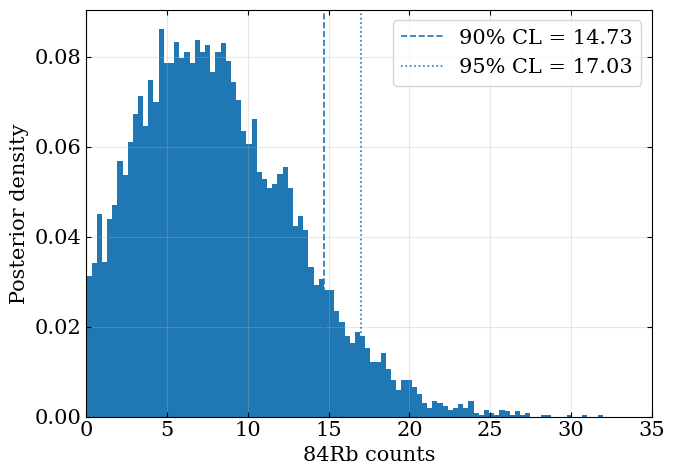

In [ ]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================
plt.figure(figsize=(7, 5))

plt.hist(Rb84_samples, bins=100, density=True)

plt.axvline(
    N_84Rb_90,
    linestyle="--",
    label=f"90% CL = {N_84Rb_90:.2f}",
)

plt.axvline(
    N_84Rb_95,
    linestyle=":",
    label=f"95% CL = {N_84Rb_95:.2f}",
)

plt.xlabel("84Rb counts")
plt.ylabel("Posterior density")
plt.grid(alpha=0.3)
plt.xlim(0,35)
plt.legend()

plt.tight_layout()
plt.show()



In [ ]:
np.median(Rb84_samples/(t_tot /(60*60*24)))

np.float64(0.0559935258513657)

In [ ]:
m_sample = 551.3 
m_sample_kg = m_sample / 1000


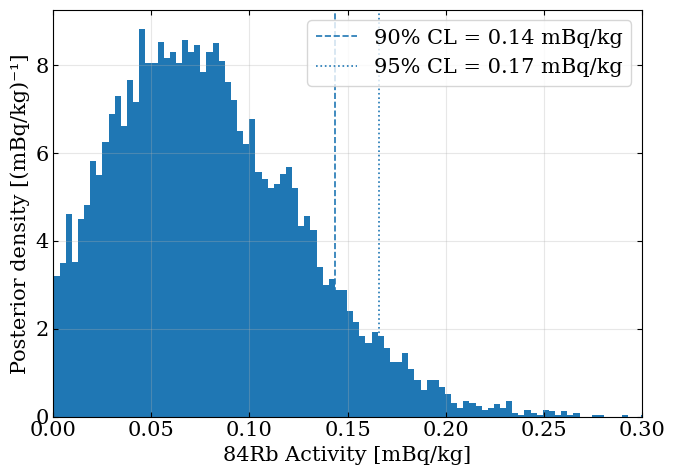

In [ ]:
# ============================================================
# SIGNAL POSTERIOR PLOT
# ============================================================

plt.figure(figsize=(7, 5))

epsilon = 0.0228
br = 0.689

# t_tot in secondi, m_sample_kg in kg
deno = t_tot * epsilon * br * m_sample_kg

activity_samples = np.asarray(Rb84_samples).ravel() * 1000 / deno

plt.hist(activity_samples, bins=100, density=True)

plt.axvline(
    np.percentile(activity_samples, 90),
    linestyle="--",
    label=f"90% CL = {np.percentile(activity_samples, 90):.2f} mBq/kg",
)

plt.axvline(
    np.percentile(activity_samples, 95),
    linestyle=":",
    label=f"95% CL = {np.percentile(activity_samples, 95):.2f} mBq/kg",
)

plt.xlabel("84Rb Activity [mBq/kg]")
plt.ylabel("Posterior density [(mBq/kg)⁻¹]")
plt.grid(alpha=0.3)
plt.xlim(0, 0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
t_tot/(60*60*24)

136.9144560185185

In [ ]:
t_tot

11829409

# Isotopes activity

In [ ]:
counts_vars = [
    v for v in trace.posterior.data_vars
    if v.startswith("A_") and v != "A_signal"
]

eff = np.array([
    0.03,    # 208Tl
    0.03,    # 84Rb
    0.0226,   # 88Y
    0.0255   # 228Ac
])

I = np.array([
    0.124,   # 208Tl — 860.56 keV
    0.690,   # 84Rb  — 881.60 keV
    0.937,   # 88Y   — 898.04 keV
    0.262    # 228Ac — 911.20 keV
])

t_tot = 4279386+7550023       # s
m_sample_kg = m_sample * 0.001

for v, epsilon, br in zip(counts_vars, eff, I):

    samples = trace.posterior[v].values.flatten()

    activity = samples / (
        t_tot
        * m_sample_kg
        * epsilon
        * br
    )

    print(
        f"{v}: "
        f"{activity.mean()*1e3:.3f} ± "
        f"{activity.std()*1e3:.3f} mBq/kg"
    )

A_²⁰⁸Tl: 0.927 ± 0.278 mBq/kg
A_⁸⁴Rb: 0.061 ± 0.036 mBq/kg
A_⁸⁸Y: 1.063 ± 0.096 mBq/kg
A_²²⁸Ac: 2.110 ± 0.256 mBq/kg


In [ ]:
samples_84Rb = trace.posterior["A_⁸⁴Rb"].values.flatten()

N90_84Rb = np.quantile(samples_84Rb, 0.90)
eff_84Rb = 0.03
I_84Rb= 0.690

A90_84Rb_mBq_kg = (
    N90_84Rb
    / (t_tot * m_sample_kg * eff_84Rb * I_84Rb)
    * 1e3
)

print(f"N90 = {N90_84Rb:.3f} counts")
print(f"84Rb 90% CL = {A90_84Rb_mBq_kg:.6f} mBq/kg")

N90 = 14.725 counts
84Rb 90% CL = 0.109080 mBq/kg
